# 2. Namsen inflow data: fitting the inflow model

The Namsen watercourse (NTE, price zone NO4) is reduced in the thesis to two equivalent reservoirs in cascade:

| reservoir | aggregates the stations | $s_{max}$ (Mm³) | $x_{max}$ (Mm³/week) | energy factor (MWh/Mm³) |
|---|---|---|---|---|
| upper (Namsvatn) | Namsvatn, Vekteren, Limingen | 458 | 74.4 | 221.5 |
| lower (Tunnsjø) | Tunnsjø, Tunnsjøflyene | 440 | 70.2 | 575.7 |

The physical constants come from the plant topology delivered with the dataset (SINTEF RenewHydro, Kong et al. 2025)
and are typed into notebook 4 directly. What has to be *estimated* is the inflow process. This notebook

1. aggregates the per-station flows (m³/s) to **weekly inflow volumes** (Mm³/week) of the two reservoirs,
2. fits the **periodic AR(1) on log inflow** per reservoir, one parameter set per week of the year, with the correlation
   between the two reservoirs' innovations,
3. checks the fitted model by simulation against the history, and
4. measures how inflow news and price news move together (the price–inflow coupling used when the lattice is built).

The real file (`data/raw/Historical_inflow.csv`, hourly since 1958) is not public; the synthetic sample in
`data/sample/inflow_daily.csv` has the same column layout at daily resolution and the loader accepts both.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gdsddp import plots
from gdsddp.data import RAW, SAMPLE, PROCESSED, save_json, load_json
plots.style()
PROCESSED.mkdir(parents=True, exist_ok=True)

In [2]:
from gdsddp.data import load_station_flows, deseasonalised_ar1_residuals, UPPER_STATIONS, LOWER_STATIONS
from gdsddp.models import InflowModel

real = RAW / "Historical_inflow.csv"
path = real if real.exists() else SAMPLE / "inflow_daily.csv"
weekly = load_station_flows(path)
weekly.to_csv(PROCESSED / "inflow_weekly.csv")
print(f"{'REAL' if path == real else 'SAMPLE'} data: {len(weekly)} weeks, {weekly.index[0].date()} to {weekly.index[-1].date()}")
print(f"annual mean inflow: upper {weekly['upper'].sum() / (len(weekly) / 52):.0f} Mm3, lower {weekly['lower'].sum() / (len(weekly) / 52):.0f} Mm3")
weekly.head()

SAMPLE data: 1825 weeks, 1990-01-14 to 2024-12-29
annual mean inflow: upper 1054 Mm3, lower 411 Mm3


,upper,lower,woy
week_ending,,,
1990-01-14,8.099136,3.003005,2
1990-01-21,9.966326,2.616192,3
1990-01-28,9.069840,2.873318,4
1990-02-04,8.422704,3.324413,5
1990-02-11,5.353776,2.612563,6


## The weekly series and its yearly profile

Inflow is dominated by the spring flood (snowmelt in May–June) and is lowest in late winter. The bands show how much
the same week varies between years; the log scale on the right panel shows why the model is written on the *log* of
the inflow: the spread is roughly proportional to the level.

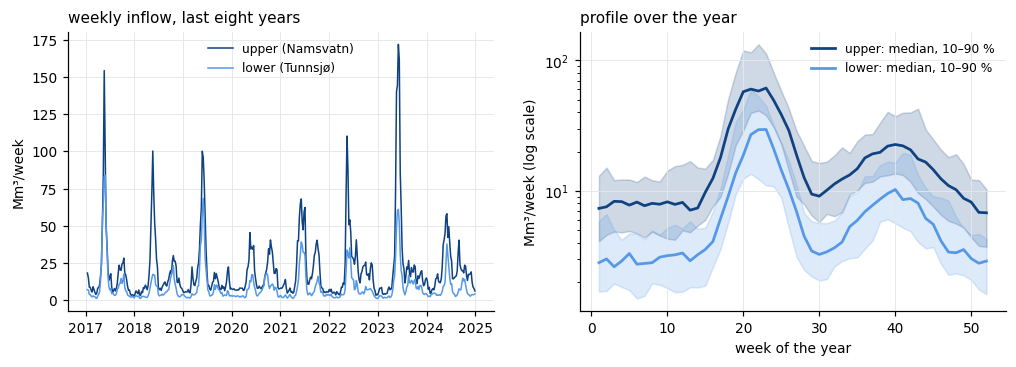

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
last = weekly.iloc[-52 * 8:]
axes[0].plot(last.index, last["upper"], color=plots.RAMP[3], lw=1, label="upper (Namsvatn)")
axes[0].plot(last.index, last["lower"], color=plots.RAMP[1], lw=1, label="lower (Tunnsjø)")
axes[0].set_ylabel("Mm³/week"); axes[0].set_title("weekly inflow, last eight years"); axes[0].legend()
w = np.arange(1, 53)
for name, col in (("upper", plots.RAMP[3]), ("lower", plots.RAMP[1])):
    g = weekly.groupby("woy")[name]
    axes[1].fill_between(w, g.quantile(0.1), g.quantile(0.9), color=col, alpha=0.2)
    axes[1].plot(w, g.median(), color=col, lw=1.8, label=f"{name}: median, 10–90 %")
axes[1].set_yscale("log"); axes[1].set_xlabel("week of the year"); axes[1].set_ylabel("Mm³/week (log scale)")
axes[1].set_title("profile over the year"); axes[1].legend();

## Fitting the periodic AR(1)

For each reservoir $r$ and each week of the year $w$:

$$\log I_{r,t} = \mu_{r,w} + \phi_{r,w}\,\log I_{r,t-1} + \sigma_{r,w}\,e_{r,t},\qquad \mathrm{corr}(e_{U,t}, e_{L,t}) = \rho_w .$$

With $N$ years of data every week has $N$ observations of the pair (last week's log inflow, this week's log inflow), and
$(\mu, \phi, \sigma)$ is the ordinary least-squares line through them. $\phi$ close to 1 means a persistent regime
(a wet week is followed by a wet week), $\sigma$ is the size of the weekly surprise. The two reservoirs share the same
weather, so their surprises are correlated ($\rho_w$ around 0.6–0.7 on the real data).

fitted on 35 years; mean phi upper 0.81 lower 0.82, mean sigma 0.25 / 0.25, mean rho 0.64


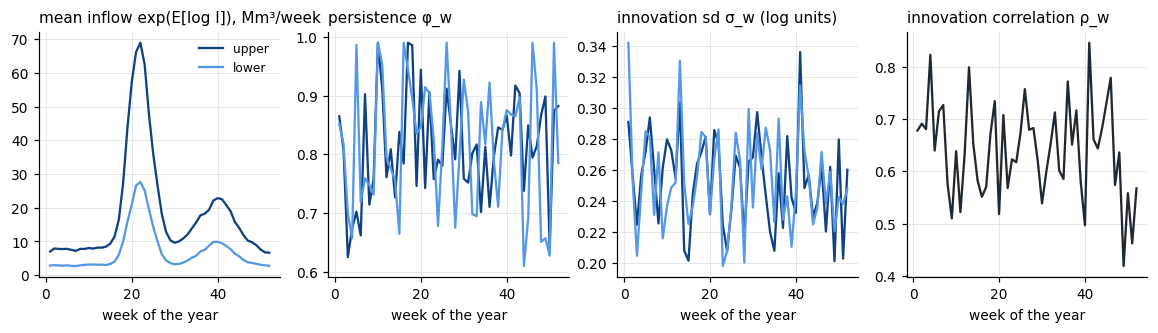

In [4]:
model = InflowModel.fit(weekly)
model.to_json(PROCESSED / "inflow_params.json")
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9))
for r, (name, col) in enumerate((("upper", plots.RAMP[3]), ("lower", plots.RAMP[1]))):
    axes[0].plot(w, np.exp(model.log_mean[r]), color=col, label=name)
    axes[1].plot(w, model.phi[r], color=col, label=name)
    axes[2].plot(w, model.sigma[r], color=col, label=name)
axes[3].plot(w, model.rho, color=plots.INK)
for ax, t in zip(axes, ("mean inflow exp(E[log I]), Mm³/week", "persistence φ_w", "innovation sd σ_w (log units)", "innovation correlation ρ_w")):
    ax.set_title(t); ax.set_xlabel("week of the year")
axes[0].legend()
print(f"fitted on {model.n_years} years; mean phi upper {model.phi[0].mean():.2f} lower {model.phi[1].mean():.2f}, "
      f"mean sigma {model.sigma[0].mean():.2f} / {model.sigma[1].mean():.2f}, mean rho {model.rho.mean():.2f}")

## Does the model reproduce the history?

We simulate 2 000 years from the fitted model and compare the median and the 10–90 % band per week with the data.
The model is a one-week-memory process, so it will not reproduce multi-year droughts, but the yearly profile and the
week-to-week spread should match.

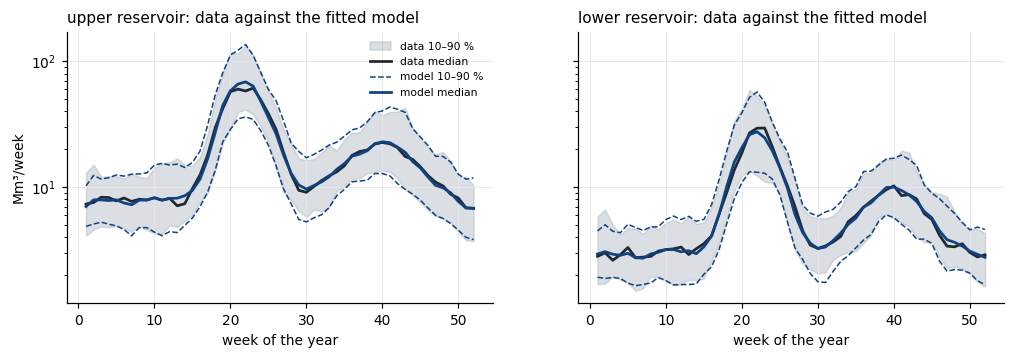

In [5]:
rng = np.random.default_rng(0)
sim = model.simulate(2000, 52, rng)                       # (paths, weeks, 2)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
for ax, (r, name) in zip(axes, enumerate(("upper", "lower"))):
    g = weekly.groupby("woy")[name]
    ax.fill_between(w, g.quantile(0.1), g.quantile(0.9), color=plots.MUTED, alpha=0.35, label="data 10–90 %")
    ax.plot(w, g.median(), color=plots.INK, lw=1.8, label="data median")
    ax.plot(w, np.quantile(sim[:, :, r], 0.1, 0), color=plots.RAMP[3], lw=1, ls="--")
    ax.plot(w, np.quantile(sim[:, :, r], 0.9, 0), color=plots.RAMP[3], lw=1, ls="--", label="model 10–90 %")
    ax.plot(w, np.median(sim[:, :, r], 0), color=plots.RAMP[3], lw=1.8, label="model median")
    ax.set_yscale("log"); ax.set_title(f"{name} reservoir: data against the fitted model"); ax.set_xlabel("week of the year")
axes[0].set_ylabel("Mm³/week"); axes[0].legend(fontsize=7);

## Price–inflow coupling

Wet weeks are cheap weeks in a hydro-dominated market. For the lattice we need the correlation between the *innovations*
(the surprises) of price and inflow, not between their levels, which both have seasons. Both series are therefore
deseasonalised with a per-week AR(1) and the residuals are correlated over the common sample. The value is stored and
used as `rho_price_inflow` in notebook 4 (the thesis finds about −0.3 on 2015–2024; it is negative but far from −1,
which is why inflow risk stays *unhedgeable* with price contracts). The synthetic sample was drawn with the same
construction at −0.3, so on the sample this cell is a recovery check.

sample inflow: using the sample price series for the coupling (the two were drawn jointly with correlation -0.3)
520 common weeks; innovation correlation price–upper -0.30, price–lower -0.15 -> rho_price_inflow = -0.22


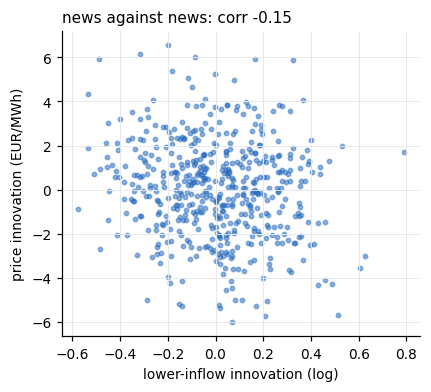

In [6]:
pw = PROCESSED / "price_weekly.csv"
from gdsddp.data import load_price_file, weekly_mean
if path == real and pw.exists():
    price_weekly = pd.read_csv(pw, parse_dates=["week_ending"]).set_index("week_ending")   # real inflow against the real price (notebook 1)
else:
    price_weekly = weekly_mean(load_price_file(SAMPLE / "system_price_daily.csv"))         # sample inflow against the SAMPLE price
    print("sample inflow: using the sample price series for the coupling (the two were drawn jointly with correlation -0.3)")
common = weekly.join(price_weekly["price"], how="inner")
woy = common["woy"].to_numpy(int)
res_p = deseasonalised_ar1_residuals(common["price"], woy)
res_u = deseasonalised_ar1_residuals(np.log(common["upper"]), woy)
res_l = deseasonalised_ar1_residuals(np.log(common["lower"]), woy)
rho_pu, rho_pl = float(np.corrcoef(res_p, res_u)[0, 1]), float(np.corrcoef(res_p, res_l)[0, 1])
rho_price_inflow = 0.5 * (rho_pu + rho_pl)
print(f"{len(common)} common weeks; innovation correlation price–upper {rho_pu:+.2f}, price–lower {rho_pl:+.2f} -> rho_price_inflow = {rho_price_inflow:+.2f}")
save_json({"rho_price_inflow": rho_price_inflow, "rho_price_upper": rho_pu, "rho_price_lower": rho_pl, "n_weeks": int(len(common)),
           "window": [str(common.index[0].date()), str(common.index[-1].date())]}, PROCESSED / "price_inflow_coupling.json")
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.scatter(res_l, res_p, s=8, color=plots.RAMP[2], alpha=0.5)
ax.set_xlabel("lower-inflow innovation (log)"); ax.set_ylabel("price innovation (EUR/MWh)"); ax.set_title(f"news against news: corr {rho_pl:+.2f}");